# Specificity of dictionary 276

Specificity is measured on the GPL whitened spectrogram of `/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav`. The dot-product sequence is first shifted and scaled by a one-minute Gaussian mean and standard deviation. A local maximum is a column where that shifted sequence is strictly larger than both neighbors. At each local maximum the ratio is the shifted value divided by the same series after convolution with a shorter Gaussian. The standard deviation `k` is half the motif width. The number for a motif is the 90th percentile of those ratios.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "evaluation" / "core.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.evaluation import evaluate_dictionary
from analysis.evaluation.core import (
    DEFAULT_CATALOG,
    DEFAULT_WAV,
    _dictionary_rows,
    _dot_products,
    _gaussian_smooth,
    _local_maxima,
    _shift_scale_dots,
    _stitch,
    _whitened_dir,
)
from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows

result = evaluate_dictionary()
percentiles = result["specificity_p90"]
distributions = result["specificity"]
sigmas = result["k"]
ids = np.array(sorted(percentiles))
values = np.array([percentiles[int(i)] for i in ids])
print(result["wav"])
print(
    f"coverage {result['coverage']:.3f}   over-coverage {result['over_coverage']:.2f}   "
    f"motifs {len(values)}"
)
print(
    f"90th-percentile specificity  min {np.nanmin(values):.3f}   "
    f"median {np.nanmedian(values):.3f}   max {np.nanmax(values):.3f}"
)


/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav
coverage 0.544   over-coverage 7.15   motifs 83
90th-percentile specificity  min 2.400   median 3.648   max 12.988


## Distribution across motifs

Each bar is the 90th percentile of one motif's specificity distribution.


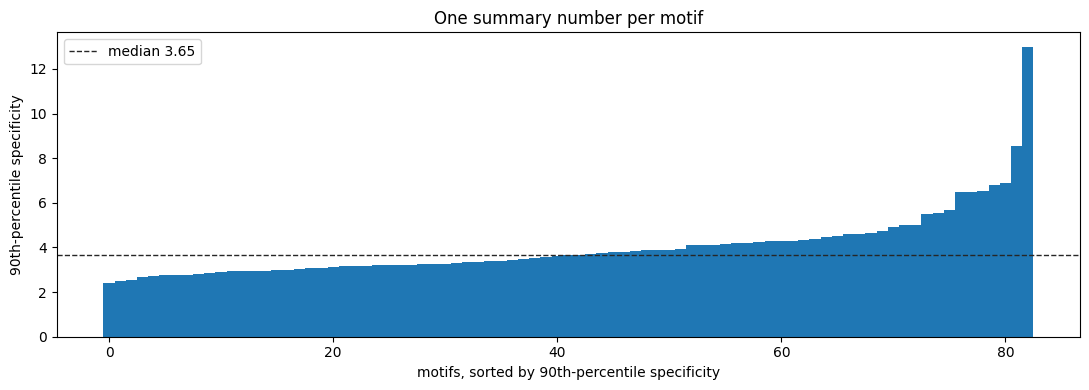

In [2]:
order = np.argsort(values)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(len(order)), values[order], color="C0", width=1.0)
ax.axhline(np.nanmedian(values), color="0.15", ls="--", lw=1, label=f"median {np.nanmedian(values):.2f}")
ax.set_xlabel("motifs, sorted by 90th-percentile specificity")
ax.set_ylabel("90th-percentile specificity")
ax.set_title("One summary number per motif")
ax.legend()
fig.tight_layout()
plt.show()


## Histogram of motif 90th percentiles

Each count is one motif. The value is the 90th percentile of that motif's specificity distribution.


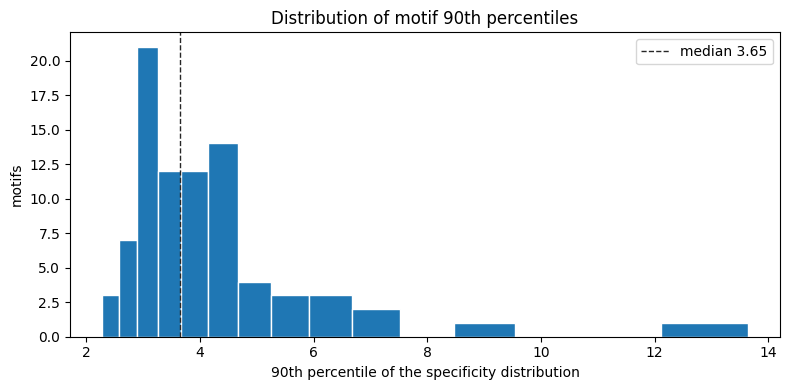

n 83   p25 3.137   median 3.648   p75 4.313


In [3]:
positive = values[np.isfinite(values) & (values > 0)]
bins = np.logspace(np.log10(positive.min() * 0.95), np.log10(max(positive.max(), positive.min() * 1.1) * 1.05), 16)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(positive, bins=bins, color="C0", edgecolor="white")
if positive.max() > 10 * positive.min():
    ax.set_xscale("log")
center = float(np.median(positive))
ax.axvline(center, color="0.15", ls="--", lw=1, label=f"median {center:.2f}")
ax.set_xlabel("90th percentile of the specificity distribution")
ax.set_ylabel("motifs")
ax.set_title("Distribution of motif 90th percentiles")
ax.legend()
fig.tight_layout()
plt.show()
print(
    f"n {positive.size}   "
    f"p25 {np.percentile(positive, 25):.3f}   "
    f"median {center:.3f}   "
    f"p75 {np.percentile(positive, 75):.3f}"
)


## Samples for a high, medium, and low motif

High is the largest 90th percentile below 10. Medium is the motif closest to the median of all the summaries. Low is the smallest 90th percentile. Values above 10 are the tail plotted in the motif grids below. For each motif the histogram is its distribution of peak ratios. The traces are three local maxima of the shifted and scaled sequence, chosen as the ones with the largest shifted values. The solid line is the shifted sequence and the dashed line is that sequence smoothed by the shorter Gaussian. The ratio is the solid value divided by the dashed value at the peak.


high    motif  81  k=21  p90=8.555  n=2396
medium  motif  53  k=15  p90=3.648  n=2110
low     motif  57  k=11  p90=2.400  n=1972


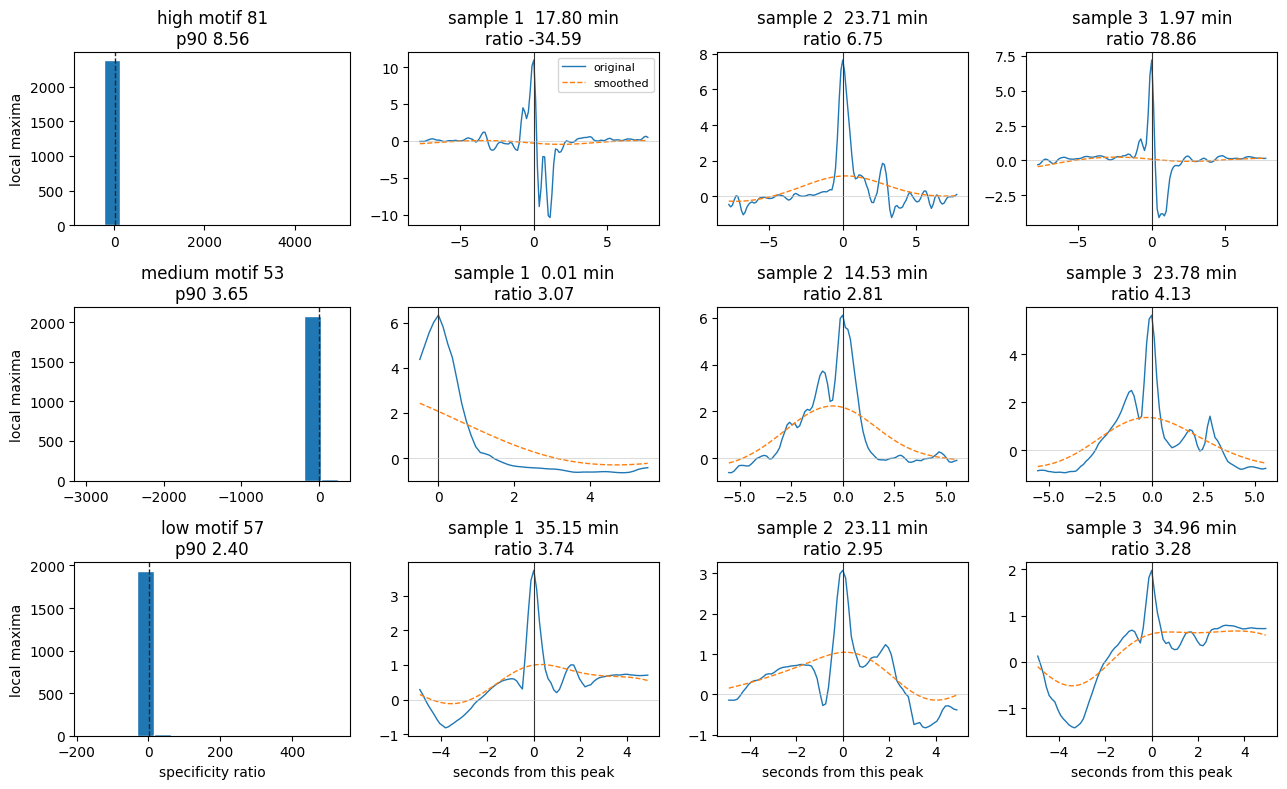

In [4]:
finite = np.isfinite(values)
high_pool = finite & (values < 10.0)
high_id = int(ids[high_pool][np.argmax(values[high_pool])])
medium_id = int(ids[finite][np.argmin(np.abs(values[finite] - np.nanmedian(values)))])
low_id = int(ids[finite][np.argmin(values[finite])])
chosen = [("high", high_id), ("medium", medium_id), ("low", low_id)]
for label, motif_id in chosen:
    print(
        f"{label:6s}  motif {motif_id:3d}  k={sigmas[motif_id]:.0f}  "
        f"p90={percentiles[motif_id]:.3f}  n={len(distributions[motif_id])}"
    )

spectrogram, _offset = _stitch(_whitened_dir(DEFAULT_CATALOG, DEFAULT_WAV))
paths = {motif_id: path for motif_id, _width, path in _dictionary_rows(DEFAULT_CATALOG, 276)}
sec_per_bin = 24576 / 200000
n_samples = 3

fig, axes = plt.subplots(len(chosen), 1 + n_samples, figsize=(13, 8), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})
for row, (label, motif_id) in enumerate(chosen):
    dots = _shift_scale_dots(
        _dot_products(spectrogram, np.load(paths[motif_id])), float(result["shift_sigma"])
    )
    sigma = float(sigmas[motif_id])
    smoothed = _gaussian_smooth(dots, sigma)
    peaks = _local_maxima(dots)
    raw = dots[peaks] / smoothed[peaks]
    usable = np.isfinite(raw)
    peaks, raw = peaks[usable], raw[usable]
    samples = peaks[np.argsort(dots[peaks])[::-1]][:n_samples]
    ax_hist = axes[row, 0]
    ax_hist.hist(distributions[motif_id], bins=15, color="C0", edgecolor="white")
    ax_hist.axvline(percentiles[motif_id], color="0.15", ls="--", lw=1)
    ax_hist.set_title(f"{label} motif {motif_id}\np90 {percentiles[motif_id]:.2f}")
    ax_hist.set_ylabel("local maxima")
    half = max(int(3 * sigma), 40)
    for col, t_star in enumerate(samples):
        ax = axes[row, col + 1]
        lo = max(0, int(t_star) - half)
        hi = min(dots.size, int(t_star) + half + 1)
        lag_s = (np.arange(lo, hi) - int(t_star)) * sec_per_bin
        ax.plot(lag_s, dots[lo:hi], color="C0", lw=1, label="original")
        ax.plot(lag_s, smoothed[lo:hi], color="C1", lw=1, ls="--", label="smoothed")
        ax.axvline(0.0, color="0.2", lw=0.8)
        ax.axhline(0.0, color="0.75", lw=0.4)
        minute = int(t_star) * sec_per_bin / 60.0
        ratio = float(dots[int(t_star)] / smoothed[int(t_star)])
        ax.set_title(f"sample {col + 1}  {minute:.2f} min\nratio {ratio:.2f}")
        if row == 0 and col == 0:
            ax.legend(fontsize=8)
axes[-1, 0].set_xlabel("specificity ratio")
for col in range(1, n_samples + 1):
    axes[-1, col].set_xlabel("seconds from this peak")
fig.tight_layout()
plt.show()


## Motifs with 90th-percentile specificity above 10

Each image is the cube root of the absolute motif, from 12 Hz to 1500 Hz, which is where these motifs are concentrated. The jet scale on each panel runs from that panel's 2nd percentile to its 98th, so the colormap covers the motif instead of a few extreme pixels.


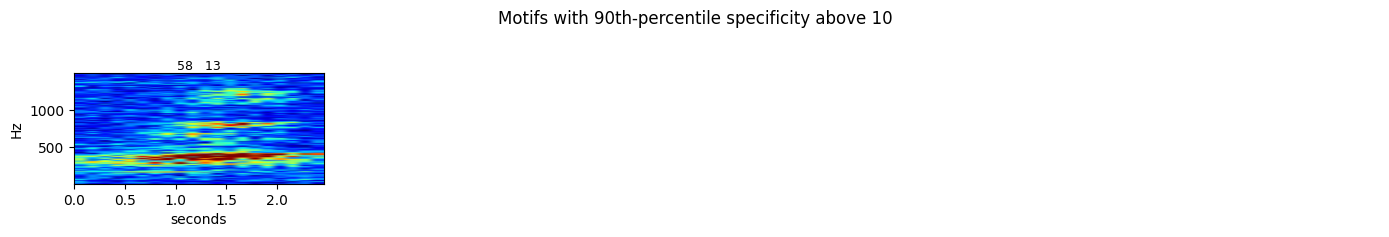

1 motifs, 12–1495 Hz


In [5]:
selected = ids[np.isfinite(values) & (values > 10.0)]
selected = selected[np.argsort(values[np.isin(ids, selected)])[::-1]]
window0 = discover_windows(_whitened_dir(DEFAULT_CATALOG, DEFAULT_WAV))[0]
freq_axis = np.linspace(0.0, float(window0.sample_freq) / 2.0, int(window0.fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(window0.start_freq))))
freqs = freq_axis[i0 : i0 + 1637]
band = np.flatnonzero(freqs <= 1500.0)
band_lo = int(band[0])
band_hi = int(band[-1]) + 1
f_lo = float(freqs[band_lo])
f_hi = float(freqs[band_hi - 1])

def draw_motifs(motif_ids, title):
    if len(motif_ids) == 0:
        print(f"{title}: none")
        return
    ncols = 5
    nrows = int(np.ceil(len(motif_ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.3 * nrows))
    axes = np.atleast_2d(axes)
    for panel, motif_id in enumerate(motif_ids):
        r, c = divmod(panel, ncols)
        ax = axes[r, c]
        atom = np.load(paths[int(motif_id)])
        shown = display_from_spwhiten(atom)[band_lo:band_hi]
        lo, hi = np.percentile(shown, [2, 98])
        if not np.isfinite(lo) or hi <= lo:
            lo, hi = float(np.min(shown)), float(np.max(shown))
        extent = [0.0, atom.shape[1] * sec_per_bin, f_lo, f_hi]
        ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
        ax.set_title(f"{int(motif_id)}   {percentiles[int(motif_id)]:.0f}", fontsize=9, pad=2)
        if c == 0:
            ax.set_ylabel("Hz")
        if r == nrows - 1:
            ax.set_xlabel("seconds")
    for panel in range(len(motif_ids), nrows * ncols):
        r, c = divmod(panel, ncols)
        axes[r, c].axis("off")
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    plt.show()
    print(f"{len(motif_ids)} motifs, {f_lo:.0f}–{f_hi:.0f} Hz")

draw_motifs(selected, "Motifs with 90th-percentile specificity above 10")


## Motifs with 90th-percentile specificity above 100

These are the motifs from the figure above whose 90th percentile is above 100, drawn the same way.


In [6]:
hot = [int(motif_id) for motif_id in selected if percentiles[int(motif_id)] > 100]
print(f"{len(hot)} of the {len(selected)} motifs above 10")
draw_motifs(hot, "Motifs with 90th-percentile specificity above 100")


0 of the 1 motifs above 10
Motifs with 90th-percentile specificity above 100: none
